# Customer Churn Prediction: Bagging vs Boosting on a Real Industry Problem

**Business problem (Telecom):** Winning a new customer typically costs several times more than keeping an existing one. The retention team can only call or send offers to a limited number of customers each month. Our job is to **rank customers by churn risk** so the team spends its budget on the right people.

**What we will do**
1. Build a baseline (Logistic Regression) and a single deep Decision Tree
2. Reduce the tree's **variance** with **Bagging** and **Random Forest**
3. Reduce **bias** with **Boosting** (AdaBoost, Gradient Boosting, HistGradientBoosting, optional XGBoost)
4. Compare models with the right metrics for imbalanced data (ROC-AUC, PR-AUC)
5. Watch boosting overfit, and stop it with early stopping
6. Choose the decision threshold using **business profit**, not the default 0.5
7. Explain the model (permutation importance) and save it for deployment



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load the data

In [7]:

df = pd.read_csv(r"C:\Users\DELL\Downloads\Customer_churn_data.csv")
df.head(3)
df.shape
df.info()
df.describe()
    
    
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # real file has blank strings
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn", "customerID"])

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Shape:", df.shape, "| churn rate:", round(y.mean(), 3))
print("Numeric:", num_cols)
print("Categorical:", cat_cols)
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Quick EDA

Churn is **imbalanced** (roughly 1 in 4 customers). Plain accuracy would be misleading: a model that says "nobody churns" is already about 75% accurate and completely useless. So we will use **ROC-AUC** and **PR-AUC** (average precision).

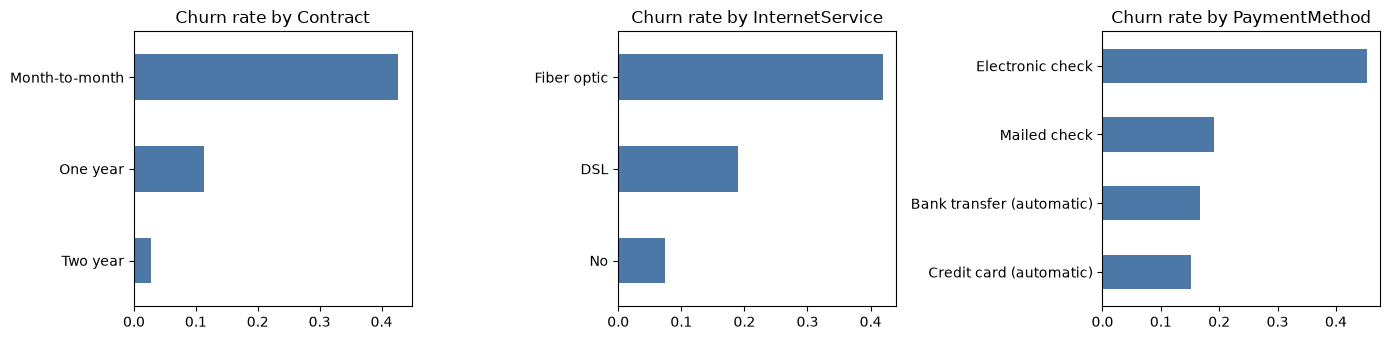

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, ["Contract", "InternetService", "PaymentMethod"]):
    df.assign(churn=y).groupby(col)["churn"].mean().sort_values().plot.barh(ax=a, color="#4C78A8")
    a.set_title(f"Churn rate by {col}")
    a.set_ylabel("")
plt.tight_layout()
plt.show()

## 3. Split the data

Stratified split keeps the churn ratio identical in train and test. **The test set stays untouched until the very end.** All model selection happens with cross-validation on the training set.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, "| train churn:", round(y_train.mean(), 3), "| test churn:", round(y_test.mean(), 3))

(5634, 19) (1409, 19) | train churn: 0.265 | test churn: 0.265


## 4. Preprocessing (inside a Pipeline, so there is no data leakage)

* **Linear model:** impute, scale numbers, one-hot encode categories.
* **Tree models:** no scaling needed. Ordinal encoding is fine for low-cardinality categories like these. For high-cardinality columns (e.g. city, product ID) use target encoding or CatBoost instead.

In [11]:
prep_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
])

## 5. The model line-up

| Model | Family | What it fixes |
|---|---|---|
| Logistic Regression | Linear baseline | The score to beat |
| Single deep Decision Tree | Single model | Shows **high variance** (overfits) |
| Bagging of deep trees | Bagging | Averages away the variance |
| Random Forest | Bagging + random features | Same, but trees are less correlated |
| AdaBoost | Boosting | Re-weights hard samples |
| Gradient Boosting | Boosting | Each tree fits the previous errors |
| HistGradientBoosting | Boosting (fast, like LightGBM) | Same idea, much faster, built-in early stopping |

In [12]:
models = {
    "Logistic Regression": Pipeline([("prep", prep_linear),
        ("m", LogisticRegression(max_iter=1000))]),

    "Decision Tree (deep)": Pipeline([("prep", prep_tree),
        ("m", DecisionTreeClassifier(random_state=RANDOM_STATE))]),

    "Bagging (200 deep trees)": Pipeline([("prep", prep_tree),
        ("m", BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=200,
                                n_jobs=-1, random_state=RANDOM_STATE))]),

    "Random Forest": Pipeline([("prep", prep_tree),
        ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                     n_jobs=-1, random_state=RANDOM_STATE))]),

    "AdaBoost": Pipeline([("prep", prep_tree),
        ("m", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=300,
                                 learning_rate=0.1, random_state=RANDOM_STATE))]),

    "Gradient Boosting": Pipeline([("prep", prep_tree),
        ("m", GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                         subsample=0.8, random_state=RANDOM_STATE))]),

    "HistGradientBoosting": Pipeline([("prep", prep_tree),
        ("m", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, early_stopping=True,
                                             random_state=RANDOM_STATE))]),
}

# Optional: XGBoost (pip install xgboost)
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = Pipeline([("prep", prep_tree),
        ("m", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                            colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1,
                            random_state=RANDOM_STATE))])
except ImportError:
    print("xgboost not installed -> skipping (run: pip install xgboost)")

print(list(models))

xgboost not installed -> skipping (run: pip install xgboost)
['Logistic Regression', 'Decision Tree (deep)', 'Bagging (200 deep trees)', 'Random Forest', 'AdaBoost', 'Gradient Boosting', 'HistGradientBoosting']


## 6. Compare with 5-fold cross-validation

Look at two things:
* **CV score:** how good is the model on unseen data?
* **Train - CV gap:** a big gap means overfitting. This is where the single tree fails and the ensembles shine.

In [14]:
rows = {}
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                       return_train_score=True)
    rows[name] = {
        "train_ROC_AUC": s["train_roc_auc"].mean(),
        "cv_ROC_AUC": s["test_roc_auc"].mean(),
        "cv_ROC_AUC_std": s["test_roc_auc"].std(),
        "cv_PR_AUC": s["test_pr_auc"].mean(),
    }

results = pd.DataFrame(rows).T
results["overfit_gap"] = results["train_ROC_AUC"] - results["cv_ROC_AUC"]
results = results.sort_values("cv_ROC_AUC", ascending=False)
results.round(3)

,train_ROC_AUC,cv_ROC_AUC,cv_ROC_AUC_std,cv_PR_AUC,overfit_gap
Gradient Boosting,0.901,0.847,0.012,0.663,0.054
AdaBoost,0.856,0.847,0.013,0.664,0.009
Logistic Regression,0.850,0.846,0.013,0.661,0.003
Random Forest,0.943,0.845,0.010,0.660,0.098
HistGradientBoosting,0.910,0.843,0.009,0.657,0.068
Bagging (200 deep trees),1.000,0.823,0.007,0.624,0.177
Decision Tree (deep),1.000,0.657,0.011,0.381,0.343


**How to read this table**
* The deep Decision Tree has train AUC near 1.0 but a much lower CV AUC. That is **variance** (memorising noise).
* Bagging and Random Forest keep the trees' flexibility but average out the noise, so the CV score jumps.
* Boosting reaches a strong CV score with *shallow* trees by reducing **bias**.
* `cv_ROC_AUC_std` shows how stable each model is across folds.
* **Be honest about the baseline:** the gap between Logistic Regression and the best ensemble can be small. Ensembles win when there are interactions and non-linear patterns (contract-renewal cliffs, price shock without support). If the effects were purely additive, the simple model would be enough.

## 7. Bagging in action: more trees never hurt (Out-of-Bag score)

Each tree in a forest never sees roughly 37% of the rows. Those rows give a **free validation score** (OOB), with no separate validation split needed.

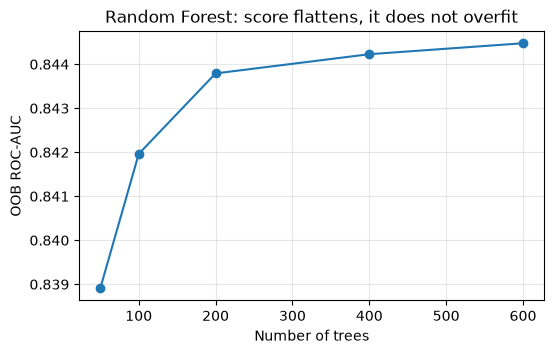

In [15]:
Xt_tree = prep_tree.fit_transform(X_train)

oob_auc = {}
for n in [50, 100, 200, 400, 600]:
    rf = RandomForestClassifier(n_estimators=n, min_samples_leaf=5, oob_score=True,
                                n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_tree, y_train)
    oob_auc[n] = roc_auc_score(y_train, rf.oob_decision_function_[:, 1])

plt.figure(figsize=(6, 3.5))
plt.plot(list(oob_auc), list(oob_auc.values()), marker="o")
plt.xlabel("Number of trees"); plt.ylabel("OOB ROC-AUC"); plt.title("Random Forest: score flattens, it does not overfit")
plt.grid(alpha=0.3); plt.show()

## 8. Boosting in action: it CAN overfit, so use early stopping

Unlike bagging, adding more boosting rounds eventually starts fitting noise. Watch the validation curve peak and then fall while the training curve keeps rising.

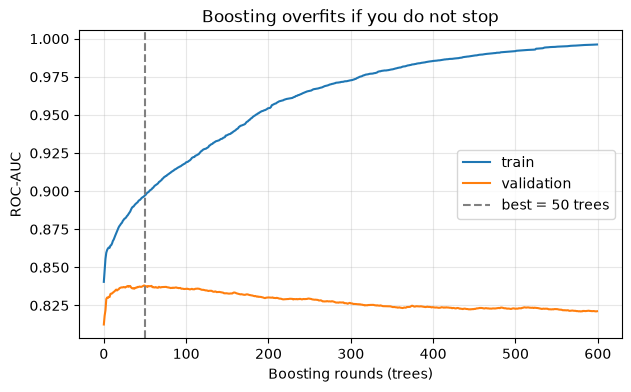

Best number of trees: 50 | val AUC: 0.8382 | val AUC at 600 trees: 0.8212


In [16]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                            stratify=y_train, random_state=RANDOM_STATE)
prep_b = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
])
A_tr, A_val = prep_b.fit_transform(X_tr), prep_b.transform(X_val)

gb = GradientBoostingClassifier(n_estimators=600, learning_rate=0.1, max_depth=4,
                                random_state=RANDOM_STATE).fit(A_tr, y_tr)

tr_curve = [roc_auc_score(y_tr, p[:, 1]) for p in gb.staged_predict_proba(A_tr)]
val_curve = [roc_auc_score(y_val, p[:, 1]) for p in gb.staged_predict_proba(A_val)]
best_n = int(np.argmax(val_curve)) + 1

plt.figure(figsize=(7, 4))
plt.plot(tr_curve, label="train"); plt.plot(val_curve, label="validation")
plt.axvline(best_n, ls="--", c="gray", label=f"best = {best_n} trees")
plt.xlabel("Boosting rounds (trees)"); plt.ylabel("ROC-AUC"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Boosting overfits if you do not stop"); plt.show()
print("Best number of trees:", best_n, "| val AUC:", round(max(val_curve), 4), "| val AUC at 600 trees:", round(val_curve[-1], 4))

This is exactly why the best practice is **small learning rate + early stopping** (what `HistGradientBoostingClassifier(early_stopping=True)` and XGBoost's `early_stopping_rounds` do for you).

## 9. Final test-set evaluation (one time only)

We pick the best **ensemble** by cross-validation (not by looking at the test set), then score every model on the test set once.

In [17]:
ensemble_names = [n for n in models if n not in ("Logistic Regression", "Decision Tree (deep)")]
best_name = results.loc[ensemble_names, "cv_ROC_AUC"].idxmax()
print("Best ensemble by CV ROC-AUC:", best_name)

test_rows = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    test_rows[name] = {"test_ROC_AUC": roc_auc_score(y_test, p),
                       "test_PR_AUC": average_precision_score(y_test, p)}

test_results = pd.DataFrame(test_rows).T.sort_values("test_ROC_AUC", ascending=False)
test_results.round(3)

Best ensemble by CV ROC-AUC: Gradient Boosting


,test_ROC_AUC,test_PR_AUC
Gradient Boosting,0.844,0.661
AdaBoost,0.844,0.665
HistGradientBoosting,0.843,0.654
Logistic Regression,0.842,0.633
Random Forest,0.840,0.648
Bagging (200 deep trees),0.809,0.603
Decision Tree (deep),0.665,0.385


## 10. From a score to a business decision: choose the threshold by profit

Default threshold 0.5 is rarely right. Retention offers cost money, and saved customers bring revenue. **Edit these assumptions for your business.**

* Customer lifetime value saved: `CLV`
* Cost of one retention offer: `OFFER_COST`
* Probability that an offer actually saves a churner: `SAVE_RATE`

We choose the threshold using **out-of-fold predictions on the training set** (not the test set), then check it once on the test set.

In [ ]:
CLV, OFFER_COST, SAVE_RATE = 500, 50, 0.40   # assumptions, not facts

def profit(y_true, proba, t):
    target = proba >= t
    tp = ((y_true == 1) & target).sum()
    fp = ((y_true == 0) & target).sum()
    return tp * (SAVE_RATE * CLV - OFFER_COST) - fp * OFFER_COST

best_pipe = models[best_name]
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

ths = np.arange(0.05, 0.90, 0.01)
curve = [profit(y_train.values, oof, t) for t in ths]
best_t = float(ths[int(np.argmax(curve))])

plt.figure(figsize=(6.5, 3.8))
plt.plot(ths, curve); plt.axvline(best_t, ls="--", c="gray", label=f"best threshold = {best_t:.2f}")
plt.xlabel("Probability threshold for sending an offer"); plt.ylabel("Profit (training OOF)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

best_pipe.fit(X_train, y_train)
p_test = best_pipe.predict_proba(X_test)[:, 1]
y_arr = y_test.values
print(f"Profit per customer on TEST:")
print(f"  target nobody            : {0:.2f}")
print(f"  target everybody         : {profit(y_arr, np.ones_like(p_test), 0.5) / len(y_arr):.2f}")
print(f"  model @ threshold 0.50   : {profit(y_arr, p_test, 0.50) / len(y_arr):.2f}")
print(f"  model @ threshold {best_t:.2f}   : {profit(y_arr, p_test, best_t) / len(y_arr):.2f}")

In [ ]:
pred = (p_test >= best_t).astype(int)
print(classification_report(y_test, pred, target_names=["stay", "churn"]))
print(pd.DataFrame(confusion_matrix(y_test, pred), index=["actual stay", "actual churn"],
                   columns=["pred stay", "pred churn"]))

## 11. Explain the model: permutation importance

Built-in tree importances are biased toward columns with many unique values. **Permutation importance** shuffles one column at a time on the test set and measures how much the score drops. It works on the raw columns, so the result is easy to explain to a business team.

In [ ]:
pi = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(6.5, 4.5))
imp.tail(10).plot.barh(color="#4C78A8")
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.title(f"Top drivers of churn ({best_name})")
plt.tight_layout(); plt.show()

## 12. Save the model (ready for a FastAPI endpoint)

In [ ]:
import joblib
joblib.dump({"model": best_pipe, "threshold": best_t, "columns": list(X.columns)}, "churn_model.joblib")
print("Saved churn_model.joblib")

## Key takeaways

1. **Bagging / Random Forest** = reduce variance. Use deep trees, train in parallel, and more trees never hurt.
2. **Boosting** = reduce bias. Use shallow trees trained in sequence, and use a small learning rate with early stopping, otherwise it overfits.
3. On imbalanced data, judge models with **ROC-AUC / PR-AUC**, never plain accuracy.
4. The threshold is a **business decision**. Optimise profit, not 0.5.
5. Do all preprocessing inside a **Pipeline** and keep the test set for one final check.
6. **Always keep a simple baseline.** If an ensemble barely beats Logistic Regression, the extra complexity may not be worth deploying.

## Try next
* Add `class_weight="balanced"` to Random Forest and compare PR-AUC
* Tune with `RandomizedSearchCV` or Optuna (`max_depth`, `learning_rate`, `min_samples_leaf`, `subsample`)
* Replace permutation importance with **SHAP** for per-customer explanations
* Swap in the real IBM Telco CSV (`USE_REAL_DATA = True`) and compare results
* Wrap `churn_model.joblib` in a FastAPI `/predict` endpoint